In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(r"C:\Projects\telecom-vendor-rebate-analytics")
RAW = ROOT / "data" / "raw"
SHOTS = ROOT / "screenshots"
REPORTING_DATE = pd.Timestamp("2026-09-30")
TERMS_DAYS = 30

def load(name):
    return pd.read_csv(RAW / f"{name}.csv")

inst = load("installation_transaction")
pol = load("po_line")
inl = load("invoice_line")
inh = load("invoice_header")
pay = load("payment")
alc = load("payment_allocation")
vendor = load("dim_vendor")

for n, d in [("installation", inst), ("po_line", pol), ("invoice_line", inl),
             ("invoice_header", inh), ("payment", pay), ("allocation", alc)]:
    print(f"{n:15s} {len(d):6d} rows")

installation      6030 rows
po_line           5322 rows
invoice_line      5788 rows
invoice_header    1772 rows
payment           1581 rows
allocation        1662 rows


In [4]:
# K1 to K4 (simple sums)
k1 = inst["expected_rebate_recorded"].sum()
k2 = pol["po_line_value"].sum()

inl2 = inl.merge(inh[["invoice_id", "invoice_status"]], on="invoice_id", how="left")
k3 = inl2.loc[inl2["invoice_status"] != "Rejected", "invoice_line_value"].sum()

alc2 = alc.merge(pay[["payment_id", "payment_status"]], on="payment_id", how="left")
valid = alc2["invoice_id"].isin(inh["invoice_id"])
k4 = alc2.loc[(alc2["payment_status"] == "Completed") & valid, "allocation_amount"].sum()

# Per-invoice balances (aggregate BEFORE merging)
inv_tot = inl.groupby("invoice_id")["invoice_line_value"].sum().rename("invoiced")
paid = (alc2[alc2["payment_status"] == "Completed"]
        .groupby("invoice_id")["allocation_amount"].sum().rename("paid"))

b = inh.set_index("invoice_id").join(inv_tot).join(paid)
b["paid"] = b["paid"].fillna(0)
b = b[b["invoice_status"].isin(["Approved", "Submitted"])].copy()
b["balance"] = b["invoiced"] - b["paid"]

inv_date = pd.to_datetime(b["invoice_date"], errors="coerce")
b["due_date"] = inv_date + pd.to_timedelta(TERMS_DAYS, unit="D")

k5 = b.loc[b["balance"] > 0, "balance"].sum()
over = b["balance"].clip(upper=0).abs().sum()
k6 = b.loc[(b["balance"] > 0) & (b["due_date"] < REPORTING_DATE), "balance"].sum()

sql = {
    "K1 Recorded rebate": 391085, "K2 PO line value": 385240,
    "K3 Invoiced, Rejected excluded": 382430, "K4 Paid to valid invoices": 345646,
    "K5 Outstanding": 43530, "Overpaid": 6746, "K6 Overdue": 29896,
}
py = {
    "K1 Recorded rebate": k1, "K2 PO line value": k2,
    "K3 Invoiced, Rejected excluded": k3, "K4 Paid to valid invoices": k4,
    "K5 Outstanding": k5, "Overpaid": over, "K6 Overdue": k6,
}

check = pd.DataFrame({"Python": py, "SQL": sql})
check["Difference"] = (check["Python"] - check["SQL"]).round(2)
check["Status"] = check["Difference"].abs().lt(0.005).map({True: "Match", False: "INVESTIGATE"})
print(check.round(2).to_string())

                                  Python     SQL  Difference Status
K1 Recorded rebate              391085.0  391085         0.0  Match
K2 PO line value                385240.0  385240         0.0  Match
K3 Invoiced, Rejected excluded  382430.0  382430         0.0  Match
K4 Paid to valid invoices       345646.0  345646         0.0  Match
K5 Outstanding                   43530.0   43530         0.0  Match
Overpaid                          6746.0    6746         0.0  Match
K6 Overdue                       29896.0   29896         0.0  Match


In [5]:
OUT = ROOT / "data" / "exports"
check.round(2).to_csv(OUT / "python_vs_sql_check.csv")
print("Saved:", OUT / "python_vs_sql_check.csv")

Saved: C:\Projects\telecom-vendor-rebate-analytics\data\exports\python_vs_sql_check.csv


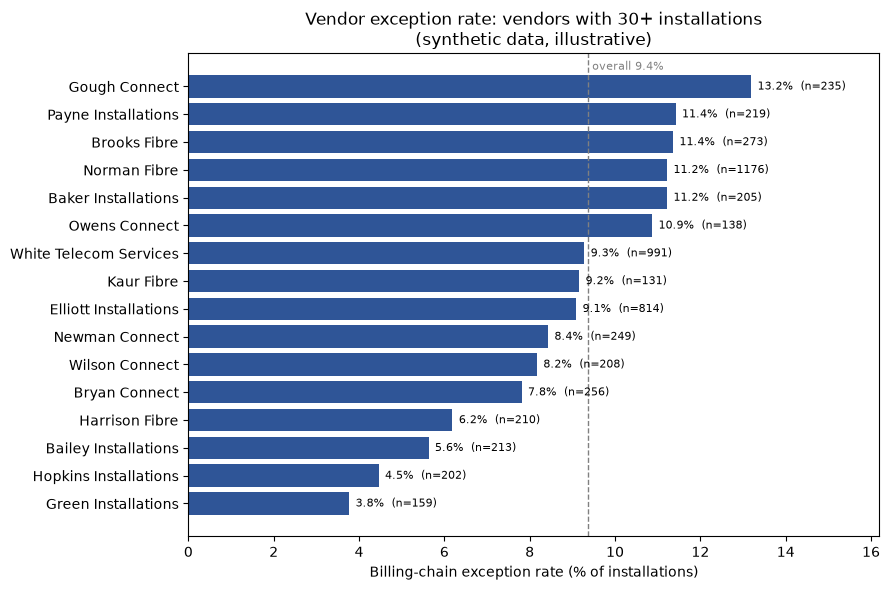

In [6]:
vr = pd.read_csv(ROOT / "data" / "exports" / "sql_vendor_exception_rate.csv")
ranked = vr[vr["volume_flag"] == "Ranked"].sort_values("exception_rate_pct")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(ranked["vendor_name"], ranked["exception_rate_pct"], color="#2F5597")
for y, (rate, n) in enumerate(zip(ranked["exception_rate_pct"], ranked["txn_count"])):
    ax.text(rate + 0.15, y, f"{rate:.1f}%  (n={n})", va="center", fontsize=8)

overall = 100 * vr["exception_count"].sum() / vr["txn_count"].sum()
ax.axvline(overall, color="grey", linestyle="--", linewidth=1)
ax.text(overall, len(ranked) - 0.4, f" overall {overall:.1f}%", color="grey", fontsize=8)

ax.set_xlabel("Billing-chain exception rate (% of installations)")
ax.set_title("Vendor exception rate: vendors with 30+ installations\n(synthetic data, illustrative)")
ax.set_xlim(0, ranked["exception_rate_pct"].max() + 3)
plt.tight_layout()
plt.savefig(SHOTS / "py_vendor_exception_rate.png", dpi=150)
plt.show()

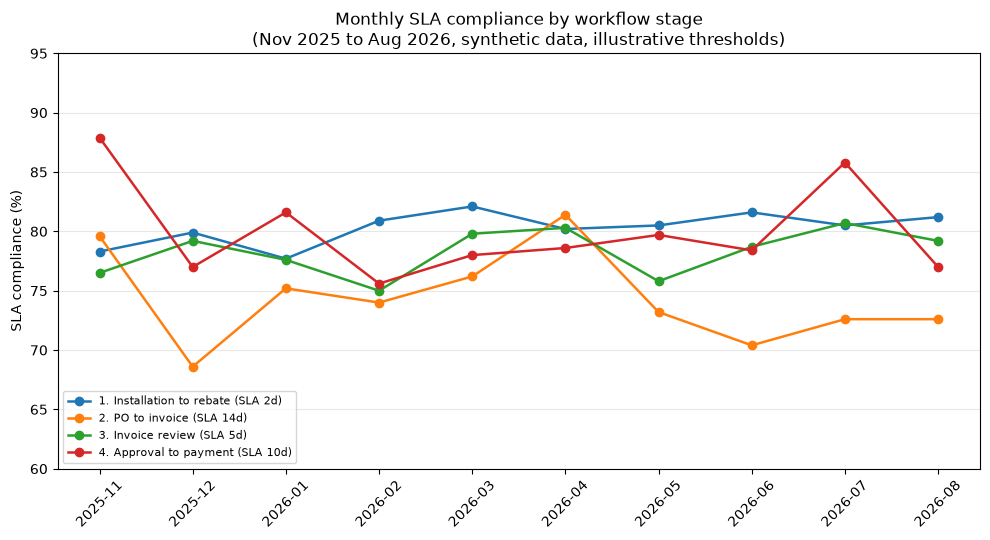

In [7]:
months = ["2025-11","2025-12","2026-01","2026-02","2026-03","2026-04",
          "2026-05","2026-06","2026-07","2026-08"]
sla = {
    "1. Installation to rebate (SLA 2d)": [78.3,79.9,77.7,80.9,82.1,80.2,80.5,81.6,80.5,81.2],
    "2. PO to invoice (SLA 14d)":         [79.6,68.6,75.2,74.0,76.2,81.4,73.2,70.4,72.6,72.6],
    "3. Invoice review (SLA 5d)":         [76.5,79.2,77.6,75.0,79.8,80.3,75.8,78.7,80.7,79.2],
    "4. Approval to payment (SLA 10d)":   [87.9,77.0,81.6,75.6,78.0,78.6,79.7,78.4,85.8,77.0],
}

fig, ax = plt.subplots(figsize=(10, 5.5))
for label, values in sla.items():
    ax.plot(months, values, marker="o", linewidth=1.8, label=label)

ax.set_ylim(60, 95)
ax.set_ylabel("SLA compliance (%)")
ax.set_title("Monthly SLA compliance by workflow stage\n(Nov 2025 to Aug 2026, synthetic data, illustrative thresholds)")
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, loc="lower left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(SHOTS / "py_monthly_sla.png", dpi=150)
plt.show()

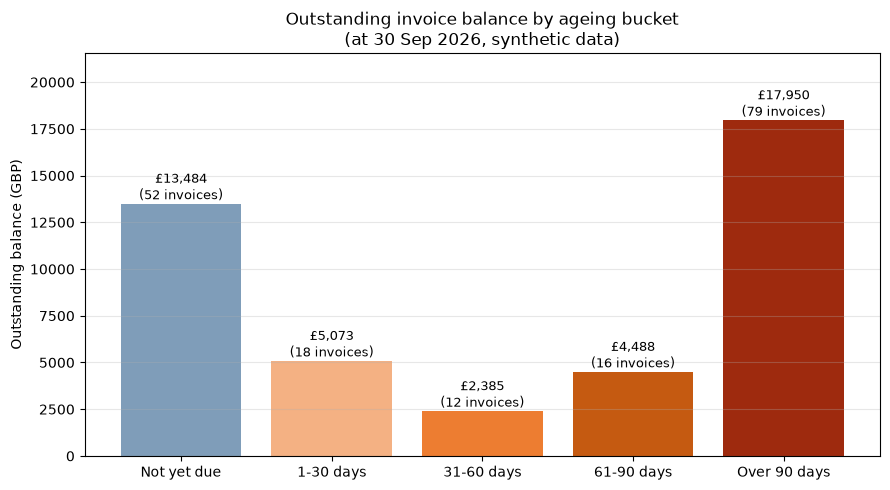

In [8]:
buckets = ["Not yet due", "1-30 days", "31-60 days", "61-90 days", "Over 90 days"]
amounts = [13484, 5073, 2385, 4488, 17950]
counts = [52, 18, 12, 16, 79]
colors = ["#7F9DB9", "#F4B183", "#ED7D31", "#C55A11", "#9E2A0E"]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(buckets, amounts, color=colors)
for bar, amt, n in zip(bars, amounts, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, amt + 250,
            f"£{amt:,}\n({n} invoices)", ha="center", fontsize=9)

ax.set_ylabel("Outstanding balance (GBP)")
ax.set_ylim(0, max(amounts) * 1.2)
ax.set_title("Outstanding invoice balance by ageing bucket\n(at 30 Sep 2026, synthetic data)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(SHOTS / "py_invoice_ageing.png", dpi=150)
plt.show()